In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
from sklearn.decomposition import PCA
import gseapy as gp

In [2]:

counts = pd.read_csv("results/gene_count_matrix.csv", index_col=0)
metadata = pd.read_csv("results/metadata.csv", index_col=0)

counts = counts.T

genes_to_keep = counts.sum(axis=0) >= 10
counts_filtered = counts.loc[:, genes_to_keep]
print(counts_filtered.shape)
print(counts_filtered.head())

(8, 24163)
gene_id     ENSG00000000003.18  ENSG00000000419.16  ENSG00000000457.16  \
SRR1039508                 699                 512                 309   
SRR1039509                 461                 550                 275   
SRR1039512                 899                 643                 365   
SRR1039513                 419                 360                 214   
SRR1039516                1179                 598                 358   

gene_id     ENSG00000000460.19  ENSG00000000971.19  ENSG00000001036.16  \
SRR1039508                 129                3330                2437   
SRR1039509                  90                3775                1693   
SRR1039512                  80                6139                2781   
SRR1039513                  64                4235                1375   
SRR1039516                 115                6705                2276   

gene_id     ENSG00000001084.15  ENSG00000001167.17  ENSG00000001460.20  \
SRR1039508               

In [3]:
dds = DeseqDataSet(counts=counts_filtered,
                   metadata=metadata,
                   design="~donor + treatment",
                   refit_cooks=True,)
dds.deseq2()

Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.00 seconds.

Fitting dispersions...
... done in 1.63 seconds.

Fitting dispersion trend curve...
... done in 0.31 seconds.

/home/amine/miniconda3/envs/airway-rnaseq/lib/python3.10/site-packages/pydeseq2/dds.py:541: UserWarning: As the residual degrees of freedom is less than 3, the distribution of log dispersions is especially asymmetric and likely to be poorly estimated by the MAD.
  self.fit_dispersion_prior()
Fitting MAP dispersions...
... done in 1.88 seconds.

Fitting LFCs...
... done in 1.64 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 0 outlier genes.



In [4]:
stat_res = DeseqStats(dds, contrast=["treatment", "dexamethasone", "untreated"])
stat_res.summary()

Running Wald tests...


Log2 fold change & Wald test p-value: treatment dexamethasone vs untreated
                       baseMean  log2FoldChange     lfcSE      stat  \
gene_id                                                               
ENSG00000000003.18   731.832022       -0.383909  0.114209 -3.361454   
ENSG00000000419.16   539.782923        0.179881  0.131447  1.368471   
ENSG00000000457.16   309.725623        0.007223  0.155398  0.046482   
ENSG00000000460.19   102.377272       -0.047649  0.284468 -0.167503   
ENSG00000000971.19  5801.238389        0.438301  0.083127  5.272669   
...                         ...             ...       ...       ...   
ENSG00000310784.1     38.865500        0.331845  0.549427  0.603983   
ENSG00000310788.1     31.097290        0.440137  1.231327  0.357449   
ENSG00000310792.1      9.187905        3.568528  2.265691  1.575029   
ENSG00000310795.1      3.901692        0.217699  1.167820  0.186415   
ENSG00000310796.1    463.169250       -0.049928  0.137321 -0.363586   

 

... done in 0.78 seconds.



In [5]:
de_results = stat_res.results_df
sig_genes = de_results[de_results["padj"] < 0.05]
print(sig_genes.shape)
print(sig_genes.sort_values("padj").head(10))

(3379, 6)
                        baseMean  log2FoldChange     lfcSE       stat  \
gene_id                                                                 
ENSG00000101347.13  14049.949397        3.763558  0.151743  24.802211   
ENSG00000120129.8    3232.580242        2.964233  0.119389  24.828462   
ENSG00000109906.17   1158.200222        7.333277  0.296119  24.764600   
ENSG00000152583.15    999.682928        4.589787  0.194333  23.618184   
ENSG00000211445.14  12152.289381        3.732211  0.158535  23.541946   
ENSG00000162614.21   5632.139945        2.032137  0.086513  23.489517   
ENSG00000189221.13   2338.846463        3.355015  0.144289  23.252094   
ENSG00000165995.25    557.825836        3.300972  0.146094  22.594783   
ENSG00000196136.20   2718.600588        3.199853  0.144464  22.149796   
ENSG00000157214.16   2951.228900        1.981962  0.089674  22.101871   

                           pvalue           padj  
gene_id                                           
ENSG0000010

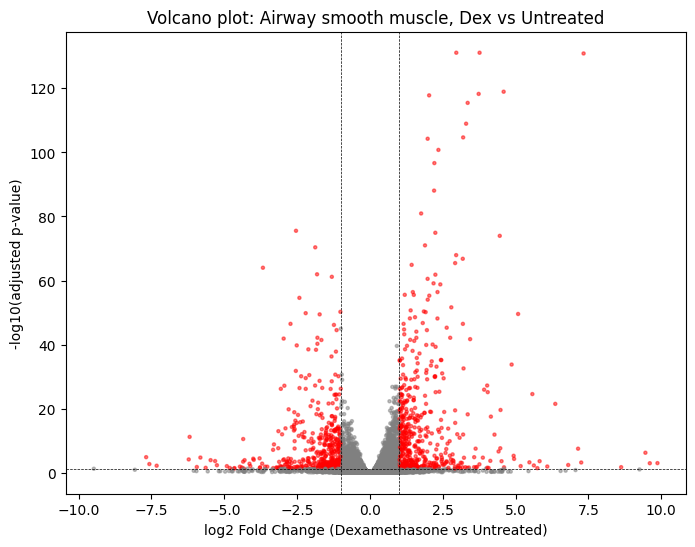

In [ ]:
de_results.to_csv("results/deseq2_results.csv")
sig_genes.to_csv("results/significant_genes.csv")

results_plot = de_results.dropna(subset=["padj"]).copy()
results_plot["neg_log10_padj"] = -np.log10(results_plot["padj"])

plt.figure(figsize=(8,6))
colors = np.where(
    (results_plot["padj"] < 0.05) & (results_plot["log2FoldChange"].abs() > 1),
    "red", "grey"
)
plt.scatter(results_plot["log2FoldChange"], results_plot["neg_log10_padj"], c=colors, s=5, alpha=0.5)
plt.axhline(-np.log10(0.05), color="black", linestyle="--", linewidth=0.5)
plt.axvline(1, color="black", linestyle="--", linewidth=0.5)
plt.axvline(-1, color="black", linestyle="--", linewidth=0.5)
plt.xlabel("log2 Fold Change (Dexamethasone vs Untreated)")
plt.ylabel("-log10(adjusted p-value)")
plt.title("Volcano plot: Airway smooth muscle, Dex vs Untreated")
plt.savefig("results/volcano_plot.png", dpi=150, bbox_inches="tight")
plt.show()

Fit type used for VST : parametric
Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.01 seconds.

Fitting dispersions...
... done in 1.77 seconds.



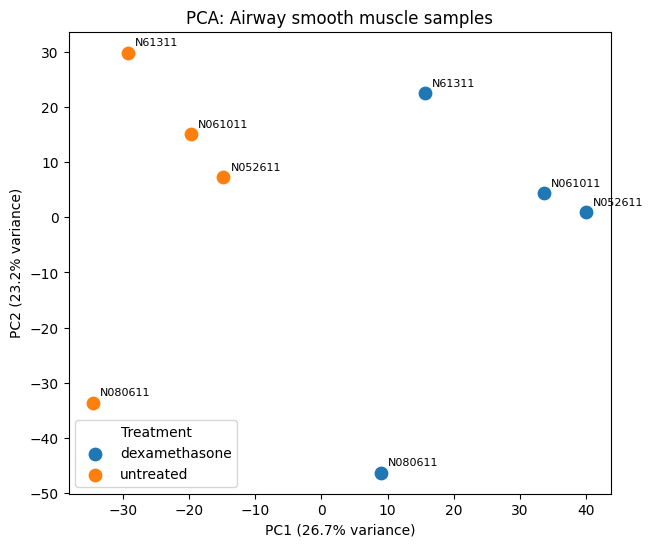

In [8]:
dds.vst()
vst_data = dds.layers["vst_counts"]

pca = PCA(n_components=2)
pca_coords = pca.fit_transform(vst_data)

pca_df = pd.DataFrame(pca_coords, columns=["PC1", "PC2"], index=counts_filtered.index)
pca_df = pca_df.join(metadata)

plt.figure(figsize=(7,6))
for treatment, group in pca_df.groupby("treatment"):
    plt.scatter(group["PC1"], group["PC2"], label=treatment, s=80)
for i, row in pca_df.iterrows():
    plt.annotate(row["donor"], (row["PC1"], row["PC2"]), fontsize=8, xytext=(5,5), textcoords="offset points")

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.title("PCA: Airway smooth muscle samples")
plt.legend(title="Treatment")
plt.savefig("results/pca_plot.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
gene2symbol = pd.read_csv("reference/gene2symbol.tsv", sep="\t", header=None, names=["gene_id", "symbol"])

sig_genes_named = sig_genes.reset_index().merge(gene2symbol, on="gene_id", how="left")
print(sig_genes_named.head())
print(sig_genes_named["symbol"].isna().sum())

              gene_id     baseMean  log2FoldChange     lfcSE      stat  \
0  ENSG00000000003.18   731.832022       -0.383909  0.114209 -3.361454   
1  ENSG00000000971.19  5801.238389        0.438301  0.083127  5.272669   
2  ENSG00000001036.16  2064.600315       -0.268688  0.083699 -3.210164   
3  ENSG00000001167.17   480.665576       -0.436218  0.130550 -3.341395   
4  ENSG00000001629.12  1751.407437       -0.229494  0.083291 -2.755323   

         pvalue      padj  symbol  
0  7.753339e-04  0.006015  TSPAN6  
1  1.344537e-07  0.000002     CFH  
2  1.326594e-03  0.009548   FUCA2  
3  8.335844e-04  0.006414    NFYA  
4  5.863415e-03  0.033243  ANKIB1  
0


In [10]:
gene_list = sig_genes_named["symbol"].dropna().unique().tolist()
gene_list = [g for g in gene_list if g != "-"]
print(len(gene_list))

3356


In [11]:
enr = gp.enrichr(
    gene_list=gene_list,
    gene_sets=["GO_Biological_Process_2021", "KEGG_2021_Human", "Reactome_2022"],
    outdir="results/enrichr",
)

enr.results.sort_values("Adjusted P-value").head(20)

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes
5793,Reactome_2022,Signal Transduction R-HSA-162582,593/2465,2.599544e-23,4.432223e-20,0,0,1.693586,88.073453,CYFIP2;NCKAP1;CYFIP1;ANKLE2;IFT172;ITSN1;H2AC1...
5477,KEGG_2021_Human,Pathways in cancer,176/531,8.133787e-21,2.570277e-18,0,0,2.539520,117.473772,RB1;FGF1;ELK1;IGF1R;EDNRA;RASSF1;CCND3;EDNRB;R...
5478,KEGG_2021_Human,Focal adhesion,88/201,1.768151e-19,2.793678e-17,0,0,3.939320,170.096635,ITGB1;TNC;PTEN;ILK;PIK3CD;LAMC2;LAMC1;ELK1;ACT...
5794,Reactome_2022,Signaling By Receptor Tyrosine Kinases R-HSA-9...,163/496,5.934244e-19,5.058943e-16,0,0,2.500490,104.941487,CYFIP2;CYFIP1;NCKAP1;SH3GL3;SPARC;IRS1;NAB1;IR...
5479,KEGG_2021_Human,Proteoglycans in cancer,85/205,4.320609e-17,4.551041e-15,0,0,3.578264,134.830939,ITGB1;CDKN1A;PIK3CD;ELK1;ACTB;ACTG1;IGF1R;PPP1...
1,GO_Biological_Process_2021,transmembrane receptor protein tyrosine kinase...,139/404,2.946608e-18,8.069286e-15,0,0,2.670578,107.800218,CYFIP2;EPHB6;CYFIP1;NCKAP1;CSF1;IRS1;ITSN1;IRS...
0,GO_Biological_Process_2021,regulation of cell migration (GO:0030334),140/408,2.901520e-18,8.069286e-15,0,0,2.660021,107.415089,SEMA5A;SERPINE2;CSF1;FAM107A;ADARB1;FGF1;CXCL1...
5480,KEGG_2021_Human,Regulation of actin cytoskeleton,85/218,3.374253e-15,2.665660e-13,0,0,3.225968,107.497664,CYFIP2;CHRM2;ITGB1;CYFIP1;NCKAP1;PIK3CD;WASL;F...
5481,KEGG_2021_Human,AGE-RAGE signaling pathway in diabetic complic...,50/100,1.838159e-14,1.161716e-12,0,0,5.019359,158.749402,PIK3CD;CASP3;AKT3;PIM1;PLCE1;RAC1;JAK2;HRAS;PR...
5795,Reactome_2022,Signaling By Rho GTPases R-HSA-194315,185/644,1.126831e-14,6.404155e-12,0,0,2.057195,66.070491,CYFIP2;CYFIP1;NCKAP1;ANKLE2;KDM1A;ITSN1;H2AC19...


In [12]:
strict_sig_genes = de_results[
    (de_results["padj"] < 0.01) & (de_results["log2FoldChange"].abs() > 1)
]
print(strict_sig_genes.shape)

strict_sig_genes.to_csv("results/significant_genes_strict.csv")

strict_named = strict_sig_genes.reset_index().merge(gene2symbol, on="gene_id", how="left")
strict_gene_list = strict_named["symbol"].dropna().unique().tolist()
strict_gene_list = [g for g in strict_gene_list if g != "-"]
print(len(strict_gene_list))

(801, 6)
799


In [13]:
enr_strict = gp.enrichr(
    gene_list=strict_gene_list,
    gene_sets=["GO_Biological_Process_2021", "KEGG_2021_Human", "Reactome_2022"],
    outdir="results/enrichr_strict",
)

enr_strict.results.sort_values("Adjusted P-value").head(20)
enr_strict.results.to_csv("results/enrichr_strict_results.csv", index=False)